# Research note：数据、检验与图表

为 `research_note.tex` 准备全部数字、表格和图。分三部分：

1. **多资产 Copula 面板检验**（本 notebook 新算）：6 类资产两两配对、互不重叠的 3 年区间，
   在「相关矩阵相同、尾部相关为 0」的高斯 Copula 零假设下，检验尾部依赖统计量是否超出普通相关。
2. **从数据库读取**各研究存下的结果（`res_*` 表）：VaR/ES 回测与 Z2 校准（studies/01）、
   股债 Copula 检验（studies/02、03）、ETF 尾部距离（studies/05）、尾部风险平价与交易成本（studies/07）。
3. 输出 `figures/*.pdf` 与 `tables/*.tex`，由 LaTeX 直接引用。

先运行 `00_data.ipynb`，以及上面列出的研究 notebook（它们会把结果写进数据库）。

In [1]:
import warnings
warnings.filterwarnings("ignore")
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import multiprocessing as mp
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
from scipy.stats import spearmanr
%run ../01_methods.ipynb

OUT = Path.cwd()
(OUT / "figures").mkdir(exist_ok=True)
(OUT / "tables").mkdir(exist_ok=True)
(OUT / "figures" / "zh").mkdir(exist_ok=True)
(OUT / "tables" / "zh").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
# 中文版图表：临时换成含中文字形的字体（Arial Unicode MS 同时覆盖拉丁字母）
RC = {"en": {}, "zh": {"font.sans-serif": ["Arial Unicode MS"], "axes.unicode_minus": False, "pdf.fonttype": 42}}
pd.set_option("display.width", 200)

## 1 · 多资产 Copula 面板检验

**数据**：沪深300、中证500、标普500、中债国债总财富、黄金（人民币计价）、布伦特原油。
A 股与海外市场收盘时间不同，日收益的同日相关会被低估，所以用**周收益**（周五收盘）。
**区间**：2005–2025，切成 7 个互不重叠的 3 年区间（每段约 156 周），15 对 × 7 段 = 105 个检验单元。

**零假设**：每个区间内，6 个资产的依赖结构是高斯 Copula，相关矩阵取该区间的正态得分相关矩阵。
它与真实数据有相同的整体相关强度（以及相关的时变——逐段匹配），但尾部相关严格为 0、上下尾对称。
在零假设下模拟同样长度的数据，对 105 个单元做同样的统计，重复 200 次，得到各汇总统计量的零分布。
这样做同时处理了两个问题：同一区间内各对共享资产、检验不独立（二项检验不适用）；以及单参数 Copula 的 λ 混有普通相关。

In [2]:
ASSETS = {"沪深300": "CSI300", "中证500": "CSI500", "标普500": "S&P500",
          "中债国债总财富": "CGB", "黄金(GLD×美元兑人民币)": "Gold", "布伦特原油": "Brent"}
px = load_prices(list(ASSETS), how="outer").rename(columns=ASSETS)
WK = px.resample("W-FRI").last().pct_change(fill_method=None).dropna()
BLOCKS = [(y, y + 2) for y in range(2005, 2024, 3)]
PAIRS = list(combinations(range(WK.shape[1]), 2))
print(f"周收益 {WK.index.min():%Y-%m-%d} ~ {WK.index.max():%Y-%m-%d}，{len(WK)} 周；"
      f"区间 {BLOCKS[0][0]}–{BLOCKS[-1][1]}，每段 {[len(WK.loc[str(a):str(b)]) for a, b in BLOCKS]} 周")


def ranks(X):
    return np.column_stack([rank_pit(X[:, k]) for k in range(X.shape[1])])


def panel_stats(U, q=0.10):
    """一个区间（T×6 的 PIT 矩阵）上 15 对的统计量。"""
    rows = []
    for i, j in PAIRS:
        u, v = U[:, i], U[:, j]
        t = t_vs_gaussian(u, v)
        s = asymmetry_test(u, v)
        c = fit_window(u, v, pit="given")
        rows.append({"i": i, "j": j, "rho": c["ns_corr"], "p_t": t["p_t"], "lam_t": t["lambda_t"],
                     "tau_L": s["tau_L"], "tau_U": s["tau_U"], "p_asym": s["p_asym"],
                     "lam_D": c["lambda_D_raw"], "lam_U": c["lambda_U_raw"],
                     "co_lo": int(((u <= q) & (v <= q)).sum()), "co_hi": int(((u > 1 - q) & (v > 1 - q)).sum())})
    return pd.DataFrame(rows)


def summarize(df):
    """把 105 个单元汇总成待检验的统计量。"""
    valid = df["p_asym"].notna()
    return pd.Series({
        "t-vs-Gaussian 拒绝数 (5%)": (df["p_t"] < 0.05).sum(),
        "平均 t 隐含尾部相关": df["lam_t"].mean(),
        "下尾同落总数": df["co_lo"].sum(),
        "上尾同落总数": df["co_hi"].sum(),
        "下尾 − 上尾同落": df["co_lo"].sum() - df["co_hi"].sum(),
        "SJC 平均 τ_L − τ_U": (df["tau_L"] - df["tau_U"]).mean(),
        "SJC 不对称拒绝数 (5%)": (df.loc[valid, "p_asym"] < 0.05).sum(),
        "平均 Clayton λ_D": df["lam_D"].mean(),
        "Spearman(λ_D, ρ)": spearmanr(df["lam_D"], df["rho"])[0],
    })


def one_sim(seed):
    rng = np.random.default_rng(seed)
    parts = [panel_stats(ranks(rng.multivariate_normal(np.zeros(len(C)), C, size=T))) for T, C in CORRS]
    return summarize(pd.concat(parts, ignore_index=True))


N_JOBS = 7
OBS, NULL_SIMS = {}, {}
for label, data in [("raw", WK), ("vol-scaled", (WK / WK.rolling(26).std().shift(1)).dropna())]:
    obs, corrs = [], []
    for a, b in BLOCKS:
        X = data.loc[str(a):str(b)].values
        U = ranks(X)
        df = panel_stats(U)
        df["block"] = f"{a}-{b}"
        obs.append(df)
        Z = norm.ppf(U)
        corrs.append((len(X), np.corrcoef(Z, rowvar=False)))
    OBS[label] = pd.concat(obs, ignore_index=True)
    global CORRS
    CORRS = corrs
    # 200 次模拟彼此独立：用 fork 出的子进程并行（子进程直接继承本进程的函数与 CORRS，不需要序列化函数）；
    # 每次模拟的随机种子固定，结果可复现
    with mp.get_context("fork").Pool(N_JOBS) as pool:
        NULL_SIMS[label] = pd.DataFrame(pool.map(one_sim, [2026 + s for s in range(200)]))
print("done")

周收益 2005-01-14 ~ 2026-10-16，1082 周；区间 2005–2025，每段 [139, 151, 148, 153, 150, 151, 150] 周


done


In [3]:
def null_table(label):
    obs = summarize(OBS[label])
    sims = NULL_SIMS[label]
    rows = {}
    for k in obs.index:
        x, s = obs[k], sims[k]
        rows[k] = {"observed": x, "null mean": s.mean(), "null 5%": s.quantile(.05), "null 95%": s.quantile(.95),
                   "p (upper)": (1 + (s >= x).sum()) / (1 + len(s)), "p (lower)": (1 + (s <= x).sum()) / (1 + len(s))}
    return pd.DataFrame(rows).T

PANEL = {k: null_table(k) for k in OBS}
save_table("panel_null_raw", PANEL["raw"])
save_table("panel_null_volscaled", PANEL["vol-scaled"])
save_table("panel_obs_raw", OBS["raw"])
pd.concat(PANEL, axis=1).round(3)

raw                                                 vol-scaled                                                
                       observed null mean  null 5% null 95% p (upper) p (lower)   observed null mean  null 5% null 95% p (upper) p (lower)
t-vs-Gaussian 拒绝数 (5%)   31.000     5.665    1.000   10.050     0.005     1.000     31.000     5.760    2.000   10.050     0.005     1.000
平均 t 隐含尾部相关               0.063     0.018    0.010    0.028     0.005     1.000      0.064     0.018    0.010    0.026     0.005     1.000
下尾同落总数                  302.000   235.445  212.000  257.050     0.005     1.000    299.000   226.485  202.000  248.050     0.005     1.000
上尾同落总数                  251.000   231.055  206.950  257.050     0.104     0.900    226.000   223.635  199.950  248.100     0.438     0.592
下尾 − 上尾同落                51.000     4.390  -25.000   32.050     0.015     0.995     73.000     2.850  -29.000   35.000     0.005     1.000
SJC 平均 τ_L − τ_U          0.049     0.000   -0.016    0.018     0.005     1.000      0.055     0.001   -0.016    0.022     0.005     1.000
SJC 不对称拒绝数 (5%)           8.000     2.390    0.000    5.000     0.005     1.000      7.000     2.310    0.000    5.000     0.010     1.000
平均 Clayton λ_D            0.096     0.082    0.073    0.093     0.015     0.990      0.094     0.079    0.070    0.089     0.020     0.985
Spearman(λ_D, ρ)          0.941     0.940    0.917    0.958     0.512     0.493      0.943     0.939    0.916    0.958     0.413     0.592

In [4]:
# 校准：周数据、约 156 个观测时 t-vs-高斯检验的误拒率（零假设下应约 5%）
SIZE156 = pd.Series({rho: (gaussian_null_t_test(window=156, n_sims=400, rho=rho, seed=k).p_t < 0.05).mean()
                     for k, rho in enumerate([0.0, 0.3, 0.6])}, name="rejection rate")
save_table("t_test_size_156", SIZE156)
SIZE156

0.0    0.0450
0.3    0.0475
0.6    0.0825
Name: rejection rate, dtype: float64

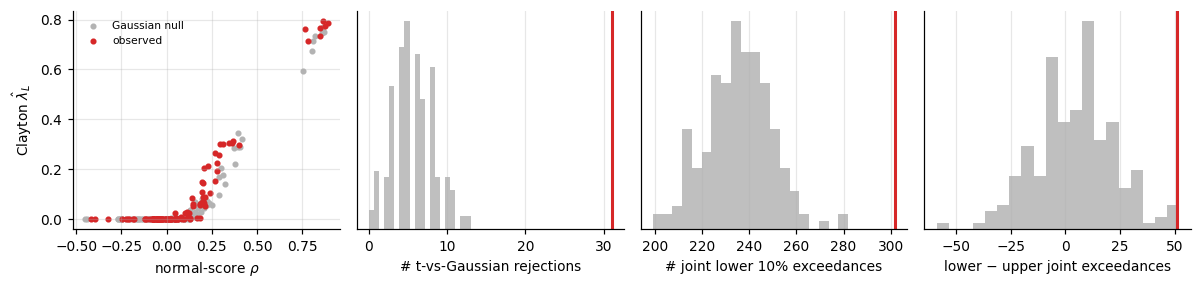

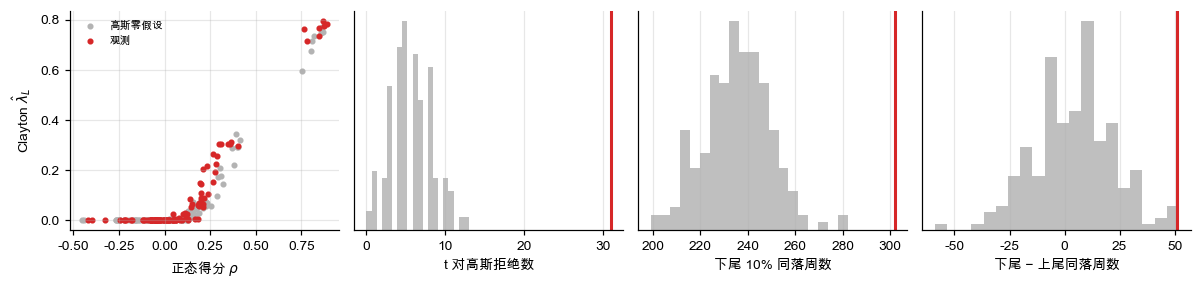

In [5]:
# 图 1：λ_D 与相关系数（观测 vs 零假设一次模拟），以及几个汇总统计量的零分布
o = OBS["raw"]
rng = np.random.default_rng(7)
null_once = pd.concat([panel_stats(ranks(rng.multivariate_normal(np.zeros(6),
                        np.corrcoef(norm.ppf(ranks(WK.loc[str(a):str(b)].values)), rowvar=False),
                        size=len(WK.loc[str(a):str(b)])))) for a, b in BLOCKS])

FIG1 = {"en": ["Gaussian null", "observed", r"normal-score $\rho$", r"Clayton $\hat\lambda_L$",
               "# t-vs-Gaussian rejections", "# joint lower 10% exceedances", "lower − upper joint exceedances"],
        "zh": ["高斯零假设", "观测", r"正态得分 $\rho$", r"Clayton $\hat\lambda_L$",
               "t 对高斯拒绝数", "下尾 10% 同落周数", "下尾 − 上尾同落周数"]}
for lang, L in FIG1.items():
    with plt.rc_context(RC[lang]):
        fig, axes = plt.subplots(1, 4, figsize=(11, 2.7))
        axes[0].scatter(null_once["rho"], null_once["lam_D"], s=9, c="0.7", label=L[0])
        axes[0].scatter(o["rho"], o["lam_D"], s=9, c="C3", label=L[1])
        axes[0].set_xlabel(L[2]); axes[0].set_ylabel(L[3])
        axes[0].legend(frameon=False, fontsize=7)
        for ax, k, lab in zip(axes[1:], ["t-vs-Gaussian 拒绝数 (5%)", "下尾同落总数", "下尾 − 上尾同落"], L[4:]):
            ax.hist(NULL_SIMS["raw"][k], bins=20, color="0.75")
            ax.axvline(summarize(o)[k], color="C3", lw=2)
            ax.set_xlabel(lab); ax.set_yticks([])
        plt.tight_layout(); fig.savefig(OUT / "figures" / ("fig_panel.pdf" if lang == "en" else "zh/fig_panel.pdf"))
        plt.show()


## 2 · 从数据库读取各研究的结果

In [6]:
VB = read_table("var_es_backtest")
VS = read_table("var_es_summary")
MC = read_table("z2_mc")
ZR = read_table("z2_real_p")
NULLC = read_table("cicc_null_compare")
AUC = read_table("lambda_auc")
BINOM = read_table("t_test_binom")
DIRN = read_table("coexceed_direction")
SJCA, SJCB = read_table("sjc_pooled_A"), read_table("sjc_pooled_B")
ETF_A, ETF_B, ETF_C = read_table("etf_lambda_vs_rho"), read_table("etf_es_aggregation"), read_table("etf_hrp_boot")
TRP, TRPB = read_table("trp_full"), read_table("trp_boot")
TCOST, TDIFF = read_table("trp_cost"), read_table("trp_cost_diff")
for name, t in [("VS", VS), ("MC", MC), ("NULLC", NULLC), ("AUC", AUC), ("BINOM", BINOM), ("DIRN", DIRN),
                ("SJCA", SJCA), ("SJCB", SJCB), ("ETF_A", ETF_A), ("ETF_B", ETF_B), ("TRP", TRP), ("TRPB", TRPB),
                ("TCOST", TCOST)]:
    print("=====", name); print(t.round(4).to_string()[:1500])

===== VS
           Kupiec 通过（p>5%）  Christoffersen 通过（p>5%）  Z2 不拒绝（p>5%）  实际损失/预测ES 中位数  99% VaR 突破率中位数
index                                                                                           
历史模拟                   5.0                      1.0           4.0         1.0310          0.0122
正态                     0.0                      0.0           0.0         1.2709          0.0183
t 分布                   3.0                      1.0           2.0         1.0009          0.0113
GPD                    5.0                      1.0           4.0         1.0270          0.0112
GARCH-FHS              7.0                      5.0           7.0         1.0261          0.0107
GARCH-EVT              7.0                      6.0           7.0         1.0336          0.0097
===== MC
                预测|  T=250|p 值检验拒绝  T=250|−0.70 规则拒绝  T=5000|p 值检验拒绝  T=5000|−0.70 规则拒绝
index                                                                                  
0              真实模型          0

In [7]:
print(TDIFF.round(4).to_string())

              口径    成本                 比较   超额夏普差  95% 下限  95% 上限  差值≤0 的比例
index                                                                      
0          每日再平衡   0bp    用 ES 代替波动率（无条件）  0.0369 -0.0261  0.1045    0.1210
1          每日再平衡   0bp    条件 TRP 相对普通风险平价  0.1260 -0.0768  0.3326    0.1095
2          每日再平衡   0bp     只加 GARCH 波动率调整  0.1083 -0.0671  0.2890    0.1115
3          每日再平衡   0bp  在条件情景上，用 ES 代替波动率  0.0178 -0.0556  0.0979    0.3060
4          每日再平衡  10bp    用 ES 代替波动率（无条件）  0.0342 -0.0287  0.1015    0.1365
5          每日再平衡  10bp    条件 TRP 相对普通风险平价  0.0755 -0.1279  0.2816    0.2245
6          每日再平衡  10bp     只加 GARCH 波动率调整  0.0605 -0.1162  0.2401    0.2470
7          每日再平衡  10bp  在条件情景上，用 ES 代替波动率  0.0150 -0.0574  0.0945    0.3275
8          每日再平衡  25bp    用 ES 代替波动率（无条件）  0.0301 -0.0332  0.0971    0.1665
9          每日再平衡  25bp    条件 TRP 相对普通风险平价 -0.0009 -0.2029  0.2051    0.4905
10         每日再平衡  25bp     只加 GARCH 波动率调整 -0.0118 -0.1899  0.1662    0.5285
11         每

## 3 · 论文表格与图

表格直接写成 `tables/*.tex`，正文 `\input`；数字全部来自上面从数据库读出的结果。

In [8]:
import re


def write_table(name, body, caption, label, colspec, header, size="\\small", fit=False, lang="en"):
    tex = "\n".join([r"\begin{table}[t]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}", size,
                      (r"\resizebox{\linewidth}{!}{" if fit else "") + rf"\begin{{tabular}}{{{colspec}}}",
                      r"\toprule", header, r"\midrule", body, r"\bottomrule",
                      r"\end{tabular}" + ("}" if fit else ""), r"\end{table}"])
    tex = re.sub(r"[+-]0\.00(?=\D)", "0.00", tex)                # 不写 −0.00 / +0.00
    (OUT / "tables" / (f"{name}.tex" if lang == "en" else f"zh/{name}.tex")).write_text(tex + "\n")
    print(tex)


# 表格文字：英文版写到 tables/，中文版写到 tables/zh/
TABLE_TEXT = {
    "en": {
        "methods": {"历史模拟": "Historical simulation", "正态": "Gaussian", "t 分布": "Student-$t$", "GPD": "GPD (POT)",
                    "GARCH-FHS": "GARCH-FHS", "GARCH-EVT": "GARCH-EVT"},
        "cap_var": "One-day-ahead VaR/ES backtests on seven assets (rolling 1{,}000-day windows). Columns 3--6 count the "
                   "assets (of 7) for which the test does not reject at 5\\%. ``Old rule'': $Z_2>-0.70$. "
                   "``Calibrated'': one-sided wild-bootstrap $p$-value of the self-normalised statistic $S$. "
                   "Last column: median over assets of mean realised loss over mean forecast ES on 97.5\\% VaR violation days.",
        "head_var": r"Method & 99\% VaR hit rate & Kupiec & Christoffersen & $Z_2$ old rule & $Z_2$ calibrated & Loss/ES \\",
        "mc_rows": {"真实模型": "Correct model", "正态尾部": "Gaussian tail, correct volatility",
                    "VaR、ES ×0.85": "VaR and ES scaled by 0.85"},
        "cap_mc": "Rejection rates of the 97.5\\% ES backtest in 1{,}000 simulations of a GARCH(1,1) with standardised "
                  "$t_5$ innovations. ``Rule'': $Z_2<-0.70$. ``Test'': one-sided asymptotic test on $S$ at 5\\%.",
        "head_mc": r"Forecast & Rule & Test & Rule & Test \\",
        "panel_rows": [r"\# $t$ vs Gaussian rejections (5\%)", r"Mean $t$-implied $\lambda$", "Joint lower-decile weeks",
                       "Joint upper-decile weeks", "Lower $-$ upper", r"Mean SJC $\hat\tau_L-\hat\tau_U$",
                       r"\# SJC asymmetry rejections (5\%)", r"Mean Clayton $\hat\lambda_L$", r"Spearman($\hat\lambda_L,\rho$)"],
        "cap_panel": "Multi-asset panel (6 assets, 15 pairs, 7 non-overlapping three-year blocks of weekly returns, 105 pair-blocks) "
                     "against the correlation-matched Gaussian-copula null (200 simulations). $p$: one-sided simulated $p$-value "
                     "(large values of the statistic). Volatility-scaled: returns divided by trailing 26-week volatility.",
        "head_panel": r" & \multicolumn{3}{c}{Raw weekly returns} & \multicolumn{3}{c}{Volatility-scaled} \\ "
                      r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}" "\n"
                      r"Statistic & Obs. & Null mean [5\%, 95\%] & $p$ & Obs. & Null mean & $p$ \\",
        "strategies": {"风险平价": "RP", "TRP-历史": "TRP (historical)", "风险平价-条件": "Conditional RP",
                       "TRP-条件": "Conditional TRP"},
        "diff_title": r"Differences in excess Sharpe, monthly buy-and-hold: estimate [95\% block-bootstrap interval]",
        "diff_rows": ["ES effect (conditional scenarios)", "ES effect (unconditional)", "Conditioning effect (volatility)",
                      "Conditional TRP $-$ RP"],
        "cap_trp": "Tail risk parity decomposition, July 2007 to October 2026, monthly targets from 500-day windows. "
                   "Turnover is realised annual one-way turnover. Excess Sharpe ratios (risk-free rate 2\\%) under monthly "
                   "rebalancing with buy-and-hold, net of the cost per unit traded shown in the column header.",
        "head_trp": r" & \multicolumn{2}{c}{Turnover} & \multicolumn{4}{c}{Excess Sharpe, cost per unit traded} \\ "
                    r"\cmidrule(lr){2-3}\cmidrule(lr){4-7}" "\n"
                    r"Strategy & Daily & Monthly & 0 bp & 10 bp & 25 bp & 50 bp \\",
    },
    "zh": {
        "methods": {"历史模拟": "历史模拟", "正态": "正态", "t 分布": "Student-$t$", "GPD": "GPD（POT）",
                    "GARCH-FHS": "GARCH-FHS", "GARCH-EVT": "GARCH-EVT"},
        "cap_var": "七个资产的一日 VaR/ES 回测（滚动 1{,}000 日窗口）。第 3--6 列为 7 个资产中该检验在 5\\% 水平下不拒绝的个数。"
                   "“旧规则”：$Z_2>-0.70$。“校准检验”：自归一化统计量 $S$ 的单侧 wild bootstrap $p$ 值。"
                   "最后一列：在 97.5\\% VaR 突破日上，平均实际损失与平均预测 ES 之比，取各资产的中位数。",
        "head_var": r"方法 & 99\% VaR 突破率 & Kupiec & Christoffersen & $Z_2$ 旧规则 & $Z_2$ 校准检验 & 损失/ES \\",
        "mc_rows": {"真实模型": "正确模型", "正态尾部": "正态尾部、波动率正确", "VaR、ES ×0.85": "VaR 与 ES 均乘以 0.85"},
        "cap_mc": "GARCH(1,1)（标准化 $t_5$ 新息）1{,}000 次模拟中 97.5\\% ES 回测的拒绝率。"
                  "“规则”：$Z_2<-0.70$。“检验”：基于 $S$ 的 5\\% 单侧渐近检验。",
        "head_mc": r"预测 & 规则 & 检验 & 规则 & 检验 \\",
        "panel_rows": [r"$t$ 对高斯拒绝数（5\%）", r"平均 $t$ 隐含 $\lambda$", "下尾 10\\% 同落周数",
                       "上尾 10\\% 同落周数", "下尾 $-$ 上尾", r"SJC 平均 $\hat\tau_L-\hat\tau_U$",
                       r"SJC 不对称拒绝数（5\%）", r"平均 Clayton $\hat\lambda_L$", r"Spearman($\hat\lambda_L,\rho$)"],
        "cap_panel": "多资产面板（6 个资产、15 对，周收益分为 7 个互不重叠的三年区间，共 105 个资产对--区间）"
                     "与相关系数匹配的高斯 copula 零假设（200 次模拟）的比较。$p$：模拟得到的单侧 $p$ 值（统计量偏大方向）。"
                     "波动率标准化：收益除以过去 26 周的波动率。",
        "head_panel": r" & \multicolumn{3}{c}{原始周收益} & \multicolumn{3}{c}{波动率标准化} \\ "
                      r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}" "\n"
                      r"统计量 & 观测值 & 零假设均值 [5\%, 95\%] & $p$ & 观测值 & 零假设均值 & $p$ \\",
        "strategies": {"风险平价": "RP", "TRP-历史": "TRP（历史）", "风险平价-条件": "条件 RP", "TRP-条件": "条件 TRP"},
        "diff_title": r"超额夏普之差（月度调仓、期间持有）：估计值 [95\% 区块 bootstrap 区间]",
        "diff_rows": ["ES 效应（条件情景）", "ES 效应（无条件情景）", "条件化效应（波动率）", "条件 TRP $-$ RP"],
        "cap_trp": "尾部风险平价分解，2007 年 7 月至 2026 年 10 月，每月末用 500 日窗口计算目标权重。换手率为实际年化单边换手。"
                   "超额夏普比率（无风险利率 2\\%）按月度调仓、期间持有口径计算，已扣除列标题所示的单位交易成本。",
        "head_trp": r" & \multicolumn{2}{c}{换手率} & \multicolumn{4}{c}{超额夏普（单位交易成本）} \\ "
                    r"\cmidrule(lr){2-3}\cmidrule(lr){4-7}" "\n"
                    r"策略 & 每日 & 月度 & 0 bp & 10 bp & 25 bp & 50 bp \\",
    },
}


for lang, TX in TABLE_TEXT.items():
    # 表 1：VaR/ES 回测（7 个资产中不拒绝的个数）
    vb = VB.copy()
    rows = []
    for m, en in TX["methods"].items():
        g = vb[vb["方法"] == m]
        rows.append(f"{en} & {g['99% VaR 突破率'].median():.2%} & {(g['Kupiec p'] > .05).sum()}/7 & "
                    f"{(g['Christoffersen p'] > .05).sum()}/7 & {(g['Z2'] > -0.70).sum()}/7 & {(g['Z2 p'] > .05).sum()}/7 & "
                    f"{g['实际损失/预测ES'].median():.2f} \\\\".replace("%", r"\%"))
    write_table("tab_varbacktest", "\n".join(rows),
                TX["cap_var"], "tab:var", "lrrrrrr", TX["head_var"], fit=True, lang=lang)

    # 表 2：Z2 蒙特卡洛
    mc = MC.set_index(MC.columns[0])
    rows = []
    for k, en in TX["mc_rows"].items():
        r = mc.loc[k]
        rows.append(f"{en} & " + " & ".join(f"{r[f'{T}|{rule}']:.1%}".replace("%", r"\%")
                    for T in ("T=250", "T=5000") for rule in ("−0.70 规则拒绝", "p 值检验拒绝")) + r" \\")
    write_table("tab_z2mc", "\n".join(rows),
                TX["cap_mc"], "tab:z2mc", "lrrrr",
                r" & \multicolumn{2}{c}{$T=250$} & \multicolumn{2}{c}{$T=5000$} \\ \cmidrule(lr){2-3}\cmidrule(lr){4-5}"
                "\n" + TX["head_mc"], lang=lang)

    # 表 3：多资产面板
    PN = [("t-vs-Gaussian 拒绝数 (5%)", "{:.0f}"),
          ("平均 t 隐含尾部相关", "{:.3f}"),
          ("下尾同落总数", "{:.0f}"),
          ("上尾同落总数", "{:.0f}"),
          ("下尾 − 上尾同落", "{:.0f}"),
          ("SJC 平均 τ_L − τ_U", "{:.3f}"),
          ("SJC 不对称拒绝数 (5%)", "{:.0f}"),
          ("平均 Clayton λ_D", "{:.3f}"),
          ("Spearman(λ_D, ρ)", "{:.2f}")]
    rows = []
    for (k, f), en in zip(PN, TX["panel_rows"]):
        a, b = PANEL["raw"].loc[k], PANEL["vol-scaled"].loc[k]
        rows.append(f"{en} & {f.format(a['observed'])} & {f.format(a['null mean'])} "
                    f"[{f.format(a['null 5%'])}, {f.format(a['null 95%'])}] & {a['p (upper)']:.3f} & "
                    f"{f.format(b['observed'])} & {f.format(b['null mean'])} & {b['p (upper)']:.3f} \\\\")
    write_table("tab_panel", "\n".join(rows),
                TX["cap_panel"], "tab:panel", "lrrrrrr", TX["head_panel"], fit=True, lang=lang)

    # 表 4：尾部风险平价
    MD, MM = "每日再平衡", "月度调仓、期间持有"
    rows = []
    for k, en in TX["strategies"].items():
        r = TCOST.loc[k]
        rows.append(f"{en} & {r[f'{MD}|年化单边换手']:.0%} & {r[f'{MM}|年化单边换手']:.0%} & "
                    + " & ".join(f"{r[f'{MM}|超额夏普 {b}bp']:.2f}" for b in (0, 10, 25, 50)) + r" \\".replace("%", ""))
    rows = [x.replace("%", r"\%") for x in rows]
    rows.append(r"\midrule")
    rows.append(r"\multicolumn{7}{l}{\emph{" + TX["diff_title"] + r"}} \\")
    DN = ["在条件情景上，用 ES 代替波动率", "用 ES 代替波动率（无条件）", "只加 GARCH 波动率调整",
          "条件 TRP 相对普通风险平价"]
    td = TDIFF[TDIFF["口径"] == MM]
    for k, en in zip(DN, TX["diff_rows"]):
        cells = []
        for b in (0, 10, 25, 50):
            r = td[(td["比较"] == k) & (td["成本"] == f"{b}bp")].iloc[0]
            cells.append(f"{r['超额夏普差']:+.2f} [{r['95% 下限']:+.2f}, {r['95% 上限']:+.2f}]")
        rows.append(rf"\multicolumn{{3}}{{l}}{{{en}}} & " + " & ".join(cells) + r" \\")
    write_table("tab_trp", "\n".join(rows),
                TX["cap_trp"], "tab:trp", "lrrrrrr", TX["head_trp"], size="\\footnotesize", fit=True, lang=lang)

\begin{table}[t]
\centering
\caption{One-day-ahead VaR/ES backtests on seven assets (rolling 1{,}000-day windows). Columns 3--6 count the assets (of 7) for which the test does not reject at 5\%. ``Old rule'': $Z_2>-0.70$. ``Calibrated'': one-sided wild-bootstrap $p$-value of the self-normalised statistic $S$. Last column: median over assets of mean realised loss over mean forecast ES on 97.5\% VaR violation days.}
\label{tab:var}
\small
\resizebox{\linewidth}{!}{\begin{tabular}{lrrrrrr}
\toprule
Method & 99\% VaR hit rate & Kupiec & Christoffersen & $Z_2$ old rule & $Z_2$ calibrated & Loss/ES \\
\midrule
Historical simulation & 1.22\% & 5/7 & 1/7 & 7/7 & 4/7 & 1.03 \\
Gaussian & 1.83\% & 0/7 & 0/7 & 6/7 & 0/7 & 1.27 \\
Student-$t$ & 1.13\% & 3/7 & 1/7 & 7/7 & 2/7 & 1.00 \\
GPD (POT) & 1.12\% & 5/7 & 1/7 & 7/7 & 4/7 & 1.03 \\
GARCH-FHS & 1.07\% & 7/7 & 5/7 & 7/7 & 7/7 & 1.03 \\
GARCH-EVT & 0.97\% & 7/7 & 6/7 & 7/7 & 7/7 & 1.03 \\
\bottomrule
\end{tabular}}
\end{table}
\begin{table}[t]
\

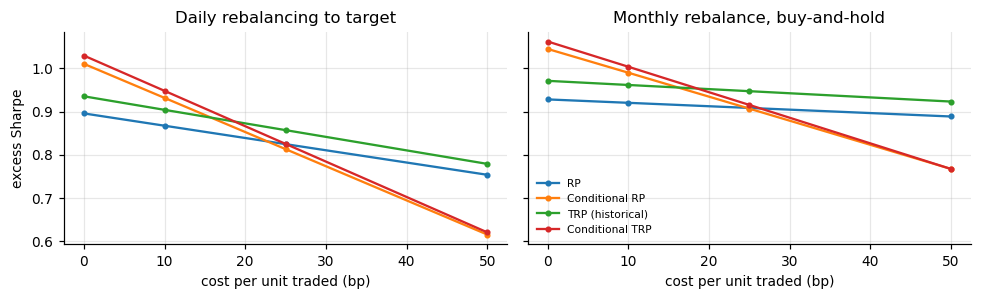

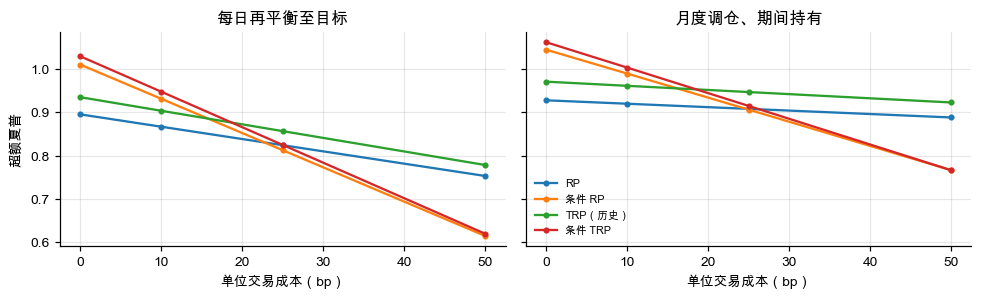

In [9]:
# 图 2：超额夏普随交易成本的变化
FIG2 = {"en": {"labels": {"风险平价": "RP", "风险平价-条件": "Conditional RP", "TRP-历史": "TRP (historical)",
                          "TRP-条件": "Conditional TRP"},
               "titles": {"每日再平衡": "Daily rebalancing to target", "月度调仓、期间持有": "Monthly rebalance, buy-and-hold"},
               "x": "cost per unit traded (bp)", "y": "excess Sharpe"},
        "zh": {"labels": {"风险平价": "RP", "风险平价-条件": "条件 RP", "TRP-历史": "TRP（历史）", "TRP-条件": "条件 TRP"},
               "titles": {"每日再平衡": "每日再平衡至目标", "月度调仓、期间持有": "月度调仓、期间持有"},
               "x": "单位交易成本（bp）", "y": "超额夏普"}}
for lang, L in FIG2.items():
    with plt.rc_context(RC[lang]):
        fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
        for ax, mode in zip(axes, ["每日再平衡", "月度调仓、期间持有"]):
            for k, lab in L["labels"].items():
                ys = [TCOST.loc[k, f"{mode}|超额夏普 {b}bp"] for b in (0, 10, 25, 50)]
                ax.plot([0, 10, 25, 50], ys, marker="o", ms=3, label=lab)
            ax.set_title(L["titles"][mode])
            ax.set_xlabel(L["x"])
        axes[0].set_ylabel(L["y"]); axes[1].legend(frameon=False, fontsize=7)
        plt.tight_layout(); fig.savefig(OUT / "figures" / ("fig_trp_costs.pdf" if lang == "en" else "zh/fig_trp_costs.pdf"))
        plt.show()
